# ACP Ejemplo Alimentación en Python
---

In [2]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [3]:
df = pd.read_excel('/Users/ppando/Materias/cs-datos/especializacion/data/Alimentacion.xlsx')
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25 entries, 0 to 24
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   País              25 non-null     object 
 1   CarneVacuna       25 non-null     float64
 2   CarneCerdo        25 non-null     float64
 3   Huevos            25 non-null     float64
 4   Leche             25 non-null     float64
 5   Pescado           25 non-null     float64
 6   Cereal            25 non-null     float64
 7   Embutidos         25 non-null     float64
 8   FrutosSecos       25 non-null     float64
 9   FrutasyVegetales  25 non-null     float64
dtypes: float64(9), object(1)
memory usage: 2.1+ KB


In [4]:
df.head()

,País,CarneVacuna,CarneCerdo,Huevos,Leche,Pescado,Cereal,Embutidos,FrutosSecos,FrutasyVegetales
0,Albania,10.1,1.4,0.5,8.9,0.2,42.3,0.6,5.5,1.7
1,Austria,8.9,14.0,4.3,19.9,2.1,28.0,3.6,1.3,4.3
2,Bélgica,13.5,9.3,4.1,17.5,4.5,26.6,5.7,2.1,4.0
3,Bulgaria,7.8,6.0,1.6,8.3,1.2,56.7,1.1,3.7,4.2
4,Checosl,9.7,11.4,2.8,12.5,2.0,34.3,5.0,1.1,4.0


In [5]:
X = df.select_dtypes(include='number')

In [6]:
X.head()

,CarneVacuna,CarneCerdo,Huevos,Leche,Pescado,Cereal,Embutidos,FrutosSecos,FrutasyVegetales
0,10.1,1.4,0.5,8.9,0.2,42.3,0.6,5.5,1.7
1,8.9,14.0,4.3,19.9,2.1,28.0,3.6,1.3,4.3
2,13.5,9.3,4.1,17.5,4.5,26.6,5.7,2.1,4.0
3,7.8,6.0,1.6,8.3,1.2,56.7,1.1,3.7,4.2
4,9.7,11.4,2.8,12.5,2.0,34.3,5.0,1.1,4.0


In [7]:
X.describe()

,CarneVacuna,CarneCerdo,Huevos,Leche,Pescado,Cereal,Embutidos,FrutosSecos,FrutasyVegetales
count,25.000000,25.000000,25.000000,25.000000,25.000000,25.000000,25.000000,25.000000,25.000000
mean,9.828000,7.896000,2.936000,17.112000,4.284000,32.248000,4.276000,3.072000,4.136000
std,3.347078,3.694081,1.117617,7.105416,3.402533,10.974786,1.634085,1.985682,1.803903
min,4.400000,1.400000,0.500000,4.900000,0.200000,18.600000,0.600000,0.700000,1.400000
25%,7.800000,4.900000,2.700000,11.100000,2.100000,24.300000,3.100000,1.500000,2.900000
50%,9.500000,7.800000,2.900000,17.600000,3.400000,28.000000,4.700000,2.400000,3.800000
75%,10.600000,10.800000,3.700000,23.300000,5.800000,40.100000,5.700000,4.700000,4.900000
max,18.000000,14.000000,4.700000,33.700000,14.200000,56.700000,6.500000,7.800000,7.900000


<Axes: title={'center': 'Boxplot de las variables numéricas del conjunto de datos Alimentación'}, xlabel='Variables', ylabel='Valores'>

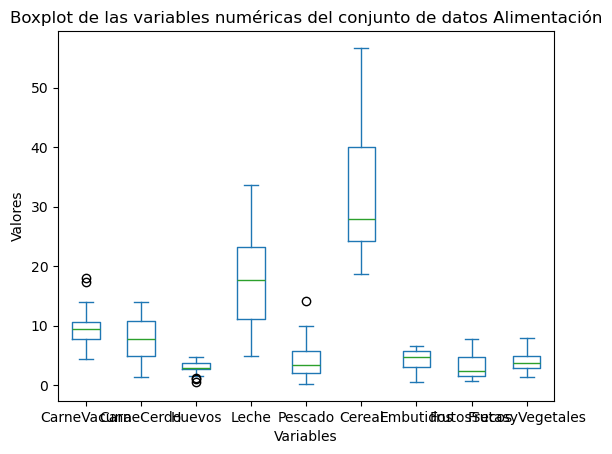

In [8]:
X.plot(kind='box', 
       ylabel='Valores', 
       xlabel='Variables', 
       title='Boxplot de las variables numéricas del conjunto de datos Alimentación')


In [9]:
# Matriz de correlación
X.corr()

,CarneVacuna,CarneCerdo,Huevos,Leche,Pescado,Cereal,Embutidos,FrutosSecos,FrutasyVegetales
CarneVacuna,1.000000,0.153003,0.585609,0.502931,0.060957,-0.499877,0.135426,-0.349449,-0.074221
CarneCerdo,0.153003,1.000000,0.620409,0.281484,-0.234009,-0.413797,0.313772,-0.634962,-0.061317
Huevos,0.585609,0.620409,1.000000,0.575533,0.065571,-0.712437,0.452231,-0.559781,-0.045518
Leche,0.502931,0.281484,0.575533,1.000000,0.137884,-0.592737,0.222411,-0.621087,-0.408364
Pescado,0.060957,-0.234009,0.065571,0.137884,1.000000,-0.524231,0.403853,-0.147153,0.266139
Cereal,-0.499877,-0.413797,-0.712437,-0.592737,-0.524231,1.000000,-0.533262,0.650997,0.046548
Embutidos,0.135426,0.313772,0.452231,0.222411,0.403853,-0.533262,1.000000,-0.474312,0.084410
FrutosSecos,-0.349449,-0.634962,-0.559781,-0.621087,-0.147153,0.650997,-0.474312,1.000000,0.374970
FrutasyVegetales,-0.074221,-0.061317,-0.045518,-0.408364,0.266139,0.046548,0.084410,0.374970,1.000000


In [10]:
# Estandarizar
scaler = StandardScaler()
Xscaled = scaler.fit_transform(X)

In [11]:
# Aplicar PCA
pca = PCA(n_components=2)
Xpca = pca.fit_transform(Xscaled)

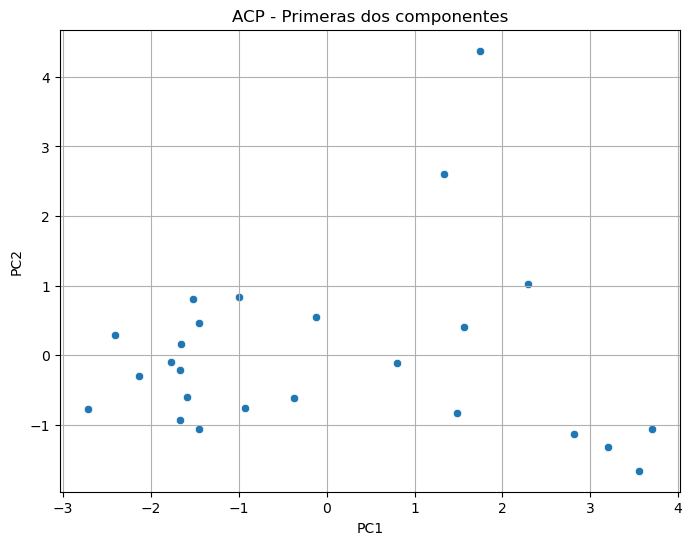

In [12]:
# Visualizar
plt.figure(figsize=(8,6))
sns.scatterplot(x=Xpca[:,0], y=Xpca[:,1])
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("ACP - Primeras dos componentes")
plt.grid(True)
plt.show()

In [13]:
# Autovalores
eigenvalues = pca.explained_variance_
eigenvalues

array([4.17337247, 1.70312442])

In [14]:
# Porcentaje de varianza explicada
explained_variance_ratio = pca.explained_variance_ratio_ * 100
explained_variance_ratio

array([44.51597304, 18.16666052])

In [15]:
# Varianza acumulada
cumulative_variance = np.cumsum(explained_variance_ratio)
cumulative_variance

array([44.51597304, 62.68263357])

* Me quedé con 2 valores explicando el 62% de la varianza y después me dedico a analizar un poco mas los otros

In [16]:
# Autovectores
eigenvectors = pca.components_
eigenvectors

array([[-0.30260939, -0.31055622, -0.42667851, -0.37772728, -0.1356499 ,
         0.43774343, -0.29724767,  0.4203344 ,  0.11041989],
       [-0.05625165, -0.23685334, -0.03533576, -0.18458877,  0.6468197 ,
        -0.23348508,  0.35282564,  0.14331056,  0.53619004]])

* Estas con las cargas (loadings) siempre van a estar entre 0 y 1
* PC1 = -0.30 * CarneVacuna - 0.31 * CarneCerdo - 0.42 * Huevos ...
* PC2 = -0.05 * CarneVacuna - 0.23 * CarneCerdo - 0.03 * Huevos ...
* Esto es para identificar a los individuos en el nuevo espacio generado por los ejes PC1 y PC2

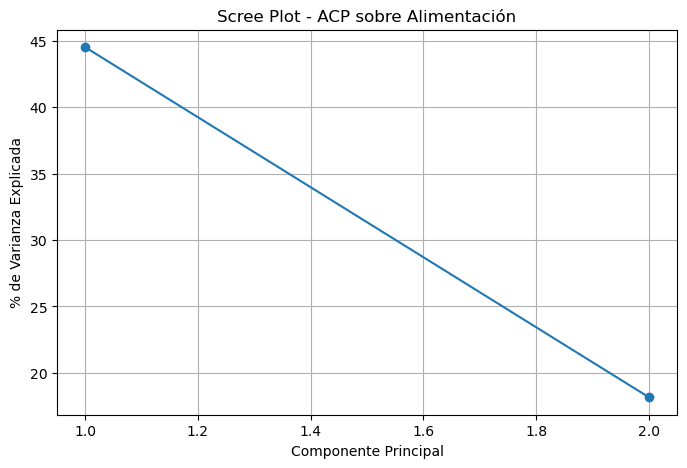

In [17]:
# Scree Plot
plt.figure(figsize=(8,5))
plt.plot(range(1, len(eigenvalues)+1), explained_variance_ratio, marker='o')
plt.title('Scree Plot - ACP sobre Alimentación')
plt.xlabel('Componente Principal')
plt.ylabel('% de Varianza Explicada')
plt.grid(True)
plt.show()

In [18]:
variables = X.columns
cos2 = (eigenvectors**2) * eigenvalues[:, np.newaxis]
cos2_df = pd.DataFrame(cos2.T, index=variables, columns=[f"PC{i+1}" for i in range(2)])
cos2_df

,PC1,PC2
CarneVacuna,0.382166,0.005389
CarneCerdo,0.402502,0.095544
Huevos,0.759781,0.002127
Leche,0.595448,0.058031
Pescado,0.076794,0.712546
Cereal,0.799699,0.092846
Embutidos,0.368743,0.212015
FrutosSecos,0.737356,0.034979
FrutasyVegetales,0.050884,0.489648


In [19]:
# Contribución de cada variable a cada componente (en %)
contrib = (cos2.T * pca.explained_variance_ratio_ * 100).T
contrib_df = pd.DataFrame(contrib.T, index=variables, columns=[f"PC{i+1}" for i in range(2)])
contrib_df

,PC1,PC2
CarneVacuna,17.012487,0.097902
CarneCerdo,17.917751,1.735723
Huevos,33.822410,0.038632
Leche,26.506948,1.054222
Pescado,3.418550,12.944580
Cereal,35.599368,1.686707
Embutidos,16.414964,3.851605
FrutosSecos,32.824105,0.635445
FrutasyVegetales,2.265154,8.895267


* %Contribución = cos2 / autovalor
* Comunalidad = Cos2Dim1 + Cos2Dim2

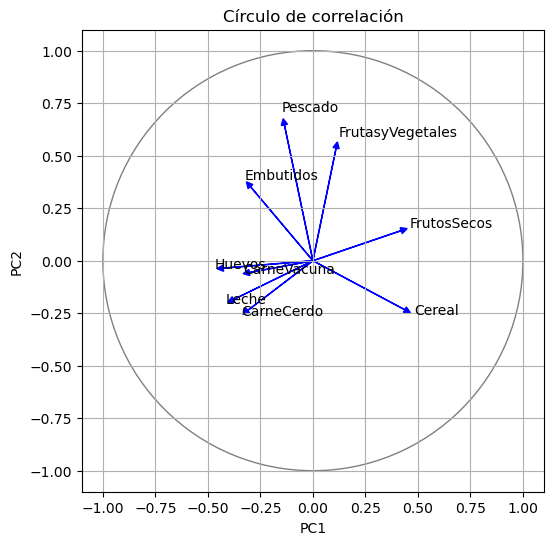

In [20]:
# Círculo de correlación
plt.figure(figsize=(6,6))
for i, var in enumerate(variables):
    plt.arrow(0, 0, eigenvectors[0, i], eigenvectors[1, i],
              head_width=0.03, head_length=0.03, fc='blue', ec='blue')
    plt.text(eigenvectors[0, i]*1.1, eigenvectors[1, i]*1.1, var, color='black')

circle = plt.Circle((0, 0), 1, color='gray', fill=False)
plt.gca().add_artist(circle)
plt.xlim(-1.1, 1.1)
plt.ylim(-1.1, 1.1)
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Círculo de correlación")
plt.grid()
plt.gca().set_aspect('equal', adjustable='box')
plt.show()

* Una variable muy cerca de centro no contribuye al análisis
* Cuanto mas cerca del circulo de radio 1, mejor va a explicar

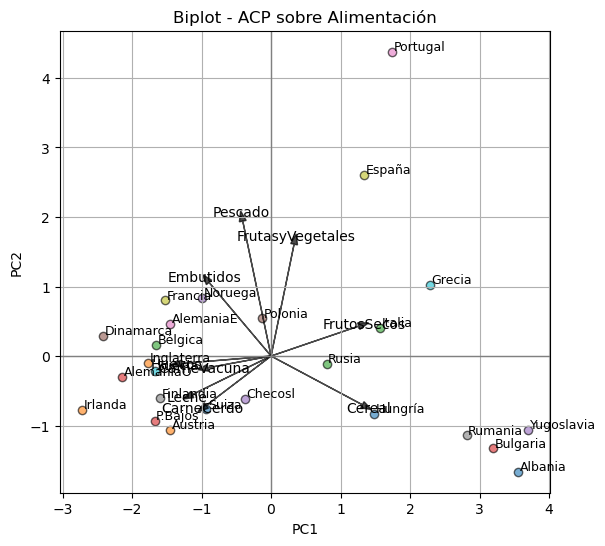

In [21]:
#Individuos+variables

# Crear biplot con colores por especie
plt.figure(figsize=(8, 6))

for idx, pais in df['País'].items():
    x, y = Xpca[idx, 0], Xpca[idx, 1]
    plt.scatter(x, y, alpha=0.6, edgecolor='k')
    plt.text(x + 0.02, y + 0.02, pais, fontsize=9)

# Graficar vectores de variables
variables = X.columns
for i in range(len(variables)):
    plt.arrow(0, 0, eigenvectors[0, i]*3, eigenvectors[1, i]*3,
              color='black', alpha=0.7, head_width=0.1)
    plt.text(eigenvectors[0, i]*3.2, eigenvectors[1, i]*3.2,
             variables[i], color='black', ha='center', va='center')

# Configurar gráfico
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Biplot - ACP sobre Alimentación")
plt.grid()
plt.axhline(0, color='gray', lw=1)
plt.axvline(0, color='gray', lw=1)
plt.gca().set_aspect('equal', adjustable='box')
plt.show()

* Grafico con variables e individuos (análisis en relación de las distancias)
* Yugoslavia y Alemania son opuestos (comportamiento de alimentación opuestos). Unos consumen mucho y otros poco
* Albania, Bulgaria, Rumania y Yugoslavia están cerca (comportamiento de alimentación parecidos)
* Portugal se diferencia de Austria
* España está cerca de las FRUTAS y VEGETALES quiere decir que está influenciado por el consumo de FRUTAS y VEGETALES
* Grecia está cerca de FRUTOS SECOS
* Importan las distancias relativas y NO importa si son positivos o negativos (importa si son opuestos o no) 